# Model Development

## A. Load clean dataset and separate target from predictors

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Load cleaned dataset
churn_df_clean = pd.read_csv(
    "../data/processed/cleaned_telco_churn.csv"
)

print("Dataset shape:", churn_df_clean.shape)

churn_df_clean.head()

Dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [62]:

churn_df_clean["SeniorCitizen"] = churn_df_clean["SeniorCitizen"].astype("object")

x = churn_df_clean.drop(columns=["Churn"])

y = churn_df_clean["Churn"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [63]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [64]:
# Identify feature types

numerical_features = x_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = x_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 3

Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 16


In [65]:
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


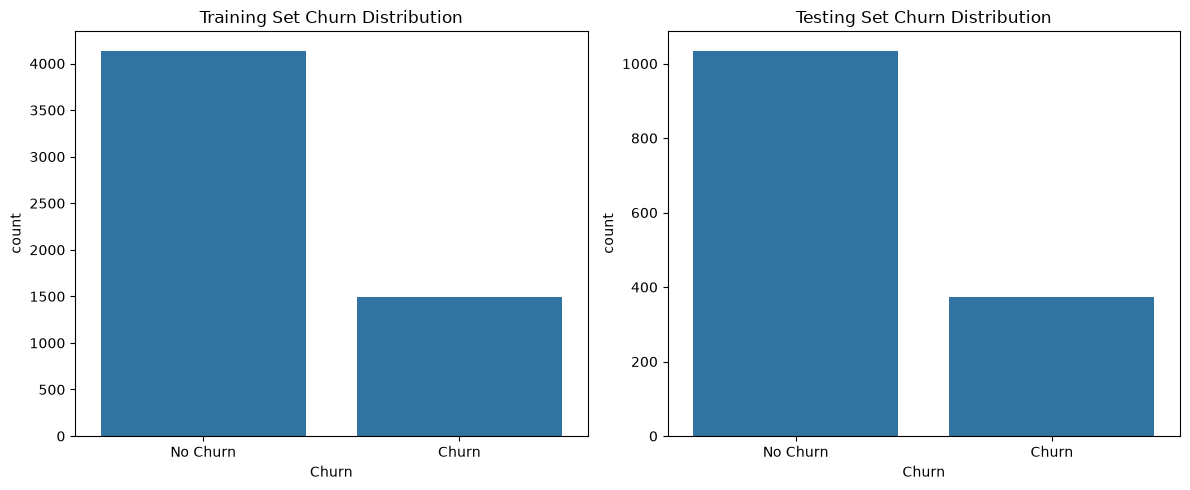

In [66]:
# Visualize the distribution of the target variable in the training and testing sets

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training Set Churn Distribution")
axes[0].set_xticks([0, 1], ["No Churn", "Churn"])

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title("Testing Set Churn Distribution")
axes[1].set_xticks([0, 1], ["No Churn", "Churn"])

plt.tight_layout()
plt.show()

In [67]:
#BUILD PREPROCESSING PIPELINES
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

## B. Carry out model development

### i) Handle class imbalance using SMOTE

In [68]:
#Establish baseline distribution of the target variable (Churn) in the training dataset.

print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Training target proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [69]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## ii) Build the two ensemble models

### Random Forest and XGBoost: Similarities and Differences

Random Forest and XGBoost are ensemble learning methods that combine many decision trees to make predictions. Both can capture nonlinear relationships and interactions between features, work well without feature scaling, and support classification tasks such as predicting customer churn.

**Random Forest** builds trees largely independently using different bootstrap samples of the training data and subsets of features. It combines their predictions by voting or averaging. This bagging approach mainly reduces variance and is often robust with relatively little tuning.

**XGBoost** builds trees sequentially, with each new tree focusing on errors or gradients from the current ensemble. It combines the trees through gradient boosting and uses regularization and other controls to limit overfitting. It can achieve strong predictive performance, but typically requires more careful tuning.

**Key difference:** Random Forest parallelizes independent trees, while XGBoost trains trees in sequence so later trees can improve on earlier ones. Both can overfit if their complexity is not controlled. In this notebook, SMOTE is applied within each training pipeline before model fitting; it is separate from how either ensemble builds trees.

### 1. Random Forest

In [70]:
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),

    ("smote", SMOTE(
        random_state=42,
        sampling_strategy="auto"
    )),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# NOTE: Random Forest combines predictions from multiple decision trees to improve predictive performance and reduce the instability of individual trees.

### 2. XGBoost

In [71]:
from xgboost import XGBClassifier

xgb_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),

    ("smote", SMOTE(random_state=42)),

    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [72]:
# Verify Implementation
print(rf_pipeline)
print(xgb_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Depende

### iii) Cross-Validation

We use 5-fold Stratified Cross-Validation to evaluate the consistency and generalization performance of the Random Forest and XGBoost classifiers.

Stratification ensures that each fold maintains approximately the same class distribution as the original training dataset.

SMOTE is applied within each training fold through the imbalanced-learn pipelines, preventing information from validation folds from influencing oversampling.

In [73]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

### 1. Cross-validate random forest

In [75]:
rf_cv_results = cross_validate(
    estimator=rf_pipeline,
    X=x_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1
)

### 2. Cross-validate XGBoost

In [78]:
xgb_cv_results = cross_validate(
    estimator=xgb_pipeline,
    X=x_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1
)

### 3. Compare both models after cross-validation

In [79]:
comparison = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Random Forest Mean": [
        rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring.keys()
    ],
    "Random Forest Std": [
        rf_cv_results[f"test_{metric}"].std()
        for metric in scoring.keys()
    ],
    "XGBoost Mean": [
        xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring.keys()
    ],
    "XGBoost Std": [
        xgb_cv_results[f"test_{metric}"].std()
        for metric in scoring.keys()
    ]
})

comparison.round(4)

,Metric,Random Forest Mean,Random Forest Std,XGBoost Mean,XGBoost Std
0,accuracy,0.7826,0.0116,0.8000,0.0094
1,precision,0.6118,0.0309,0.6409,0.0265
2,recall,0.4977,0.0209,0.5632,0.0266
3,f1,0.5485,0.0213,0.5989,0.0183
4,roc_auc,0.8167,0.0134,0.8442,0.0095


### 4. Train final models

In [81]:
rf_pipeline.fit(x_train, y_train)

xgb_pipeline.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


### 5. Save the trained pipelines



In [82]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_pipeline,
    "../models/random_forest_churn.pkl"
)

joblib.dump(
    xgb_pipeline,
    "../models/xgboost_churn.pkl"
)

['../models/xgboost_churn.pkl']

## Overall Conclusion

This workflow prepared and compared two tree-based classifiers for predicting customer churn. We first made a stratified 80/20 train-test split so that both partitions retained a similar churn proportion. Within each model pipeline, numerical features were median-imputed, categorical features were imputed with their most frequent values and one-hot encoded, and SMOTE was applied during training to address class imbalance. Keeping preprocessing and resampling inside the pipelines allowed cross-validation to fit these steps on each training fold only.

We compared Random Forest and XGBoost using five-fold stratified cross-validation on the training partition. Results are reported as mean (standard deviation) across folds:

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Accuracy | 0.7826 (0.0116) | **0.8000 (0.0094)** |
| Precision | 0.6118 (0.0309) | **0.6409 (0.0265)** |
| Recall | 0.4977 (0.0209) | **0.5632 (0.0266)** |
| F1 score | 0.5485 (0.0213) | **0.5989 (0.0183)** |
| ROC-AUC | 0.8167 (0.0134) | **0.8442 (0.0095)** |

XGBoost achieved higher mean scores on all five metrics, with relatively low fold-to-fold variation, making it the stronger candidate based on this cross-validation comparison. Its recall of 0.5632 is still moderate, so the current decision threshold may miss a substantial share of customers who churn. The choice of a final model should account for the business cost of missed churners versus false alerts.

After cross-validation, both pipelines were fitted on the full training partition and saved as `models/random_forest_churn.pkl` and `models/xgboost_churn.pkl`. These figures are cross-validation results, not final test-set results: the held-out test partition has not yet been used for final evaluation. Evaluate the selected model on that partition before making claims about expected performance on unseen customers. Also review the use of standard SMOTE after one-hot encoding, since synthetic samples may not preserve valid categorical feature combinations.